In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("cleaned_expression.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Shape: (51, 28280)

First 5 rows:


,Unnamed: 0,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2MP1,A3GALT2,A4GALT,...,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3,Response
0,F71B-Tn-C_S2,50,13,3,11275,48,5851,1,6,146,...,59,325,419,661,533,736,983,4222,2678,1
1,X116BBp-C_S11,42,3,3,14324,182,43,0,2,107,...,343,386,406,1036,211,1001,1419,5564,2709,1
2,X090B-Bn_S6,226,71,0,22473,106,17,0,1,363,...,177,235,323,1119,586,1518,1465,6632,4455,0
3,X047B-Bn-C_S3,121,39,1,12556,121,6,1,1,190,...,222,303,630,736,119,785,1543,4367,2250,1
4,X260B-Bp-C_S5,70,25,17,19076,94,9,0,0,102,...,698,386,647,758,367,1194,1312,5735,2547,1


In [3]:
print("Columns:", df.shape[1])
print("Rows:", df.shape[0])

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nTarget distribution:")
print(df["Response"].value_counts())

print("\nTarget classes:")
print(df["Response"].unique())

Columns: 28280
Rows: 51

Missing values:
0

Target distribution:
Response
0    26
1    25
Name: count, dtype: int64

Target classes:
[1 0]


In [4]:
# Step 4: Remove Sample ID column

df = df.drop(columns=["Unnamed: 0"])

print("Shape after removing Sample ID:")
print(df.shape)

print("\nRemaining first 5 columns:")
print(df.columns[:5])

Shape after removing Sample ID:
(51, 28279)

Remaining first 5 columns:
Index(['A1BG', 'A1BG-AS1', 'A1CF', 'A2M', 'A2M-AS1'], dtype='object')


In [5]:
X = df.drop(columns=["Response"])
y = df["Response"]

print("Features X:", X.shape)
print("Target y:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features X: (51, 28278)
Target y: (51,)

Target distribution:
Response
0    26
1    25
Name: count, dtype: int64


In [6]:
X = X.replace([np.inf, -np.inf], np.nan)

X = X.fillna(X.median())

print("Missing values after preprocessing:")
print(X.isnull().sum().sum())

Missing values after preprocessing:
0


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (40, 28278)
Testing data: (11, 28278)

Training target distribution:
Response
0    20
1    20
Name: count, dtype: int64

Testing target distribution:
Response
0    6
1    5
Name: count, dtype: int64


In [8]:
k = min(500, X_train.shape[1])

selector = SelectKBest(
    score_func=f_classif,
    k=k
)

X_train_selected = selector.fit_transform(
    X_train,
    y_train
)

X_test_selected = selector.transform(
    X_test
)

selected_features = X.columns[
    selector.get_support()
]

print("Original number of genes:", X_train.shape[1])
print("Selected number of genes:", X_train_selected.shape[1])

C:\Users\revat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [   10   229   301 ... 27803 28179 28225] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
C:\Users\revat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


Original number of genes: 28278
Selected number of genes: 500


In [9]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(
    X_train_selected,
    y_train
)

rf_prediction = rf_model.predict(
    X_test_selected
)

print("Random Forest training completed!")

Random Forest training completed!


In [10]:
rf_accuracy = accuracy_score(
    y_test,
    rf_prediction
)

rf_precision = precision_score(
    y_test,
    rf_prediction,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_prediction,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_prediction,
    zero_division=0
)

print("========== RANDOM FOREST ==========")

print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1-Score :", round(rf_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_prediction,
        zero_division=0
    )
)

========== RANDOM FOREST ==========
Accuracy : 0.6364
Precision: 0.5714
Recall   : 0.8
F1-Score : 0.6667

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.50      0.60         6
           1       0.57      0.80      0.67         5

    accuracy                           0.64        11
   macro avg       0.66      0.65      0.63        11
weighted avg       0.67      0.64      0.63        11



In [11]:
feature_importance = pd.DataFrame({
    "Gene": selected_features,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 important genes:")
display(feature_importance.head(10))

Top 10 important genes:


,Gene,Importance
295,MYOT,0.021857
365,RBM5-AS1,0.021799
185,H2BC12,0.021235
221,KRTAP5-2,0.017335
441,TCTE3,0.015003
50,C1QC,0.013678
328,PACRGL,0.013079
59,C8orf37,0.012547
473,USP17L7,0.012383
81,CFAP69,0.011524


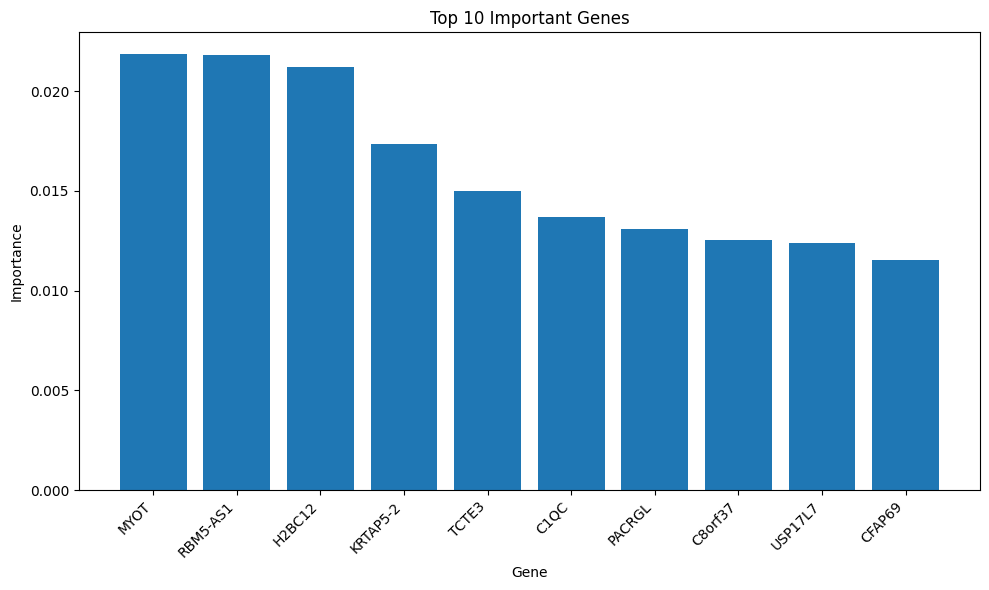

In [12]:
top10 = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.bar(
    top10["Gene"],
    top10["Importance"]
)

plt.xlabel("Gene")
plt.ylabel("Importance")
plt.title("Top 10 Important Genes")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train_selected
)

X_test_scaled = scaler.transform(
    X_test_selected
)

print("Feature scaling completed!")

Feature scaling completed!


In [14]:
svm_model = SVC(
    kernel="rbf",
    random_state=42
)

svm_model.fit(
    X_train_scaled,
    y_train
)

svm_prediction = svm_model.predict(
    X_test_scaled
)

print("SVM training completed!")

SVM training completed!


In [15]:
svm_model = SVC(
    kernel="rbf",
    random_state=42
)

svm_model.fit(
    X_train_scaled,
    y_train
)

svm_prediction = svm_model.predict(
    X_test_scaled
)

print("SVM training completed!")

SVM training completed!


In [16]:
svm_accuracy = accuracy_score(
    y_test,
    svm_prediction
)

svm_precision = precision_score(
    y_test,
    svm_prediction,
    zero_division=0
)

svm_recall = recall_score(
    y_test,
    svm_prediction,
    zero_division=0
)

svm_f1 = f1_score(
    y_test,
    svm_prediction,
    zero_division=0
)

print("============== SVM ==============")

print("Accuracy :", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("F1-Score :", round(svm_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        svm_prediction,
        zero_division=0
    )
)

============== SVM ==============
Accuracy : 0.7273
Precision: 0.625
Recall   : 1.0
F1-Score : 0.7692

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.50      0.67         6
           1       0.62      1.00      0.77         5

    accuracy                           0.73        11
   macro avg       0.81      0.75      0.72        11
weighted avg       0.83      0.73      0.71        11



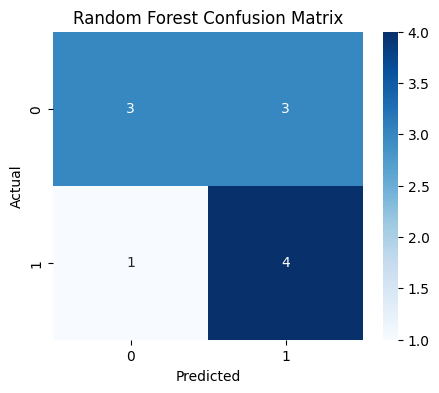

In [17]:
rf_cm = confusion_matrix(
    y_test,
    rf_prediction
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

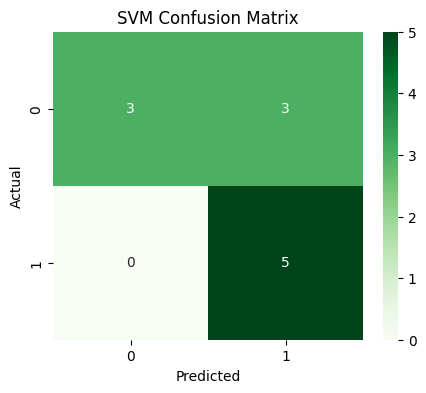

In [18]:
svm_cm = confusion_matrix(
    y_test,
    svm_prediction
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")

plt.show()

In [19]:
comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "SVM"
    ],
    "Accuracy": [
        rf_accuracy,
        svm_accuracy
    ],
    "Precision": [
        rf_precision,
        svm_precision
    ],
    "Recall": [
        rf_recall,
        svm_recall
    ],
    "F1-Score": [
        rf_f1,
        svm_f1
    ]
})

display(comparison)

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.636364,0.571429,0.8,0.666667
1,SVM,0.727273,0.625000,1.0,0.769231


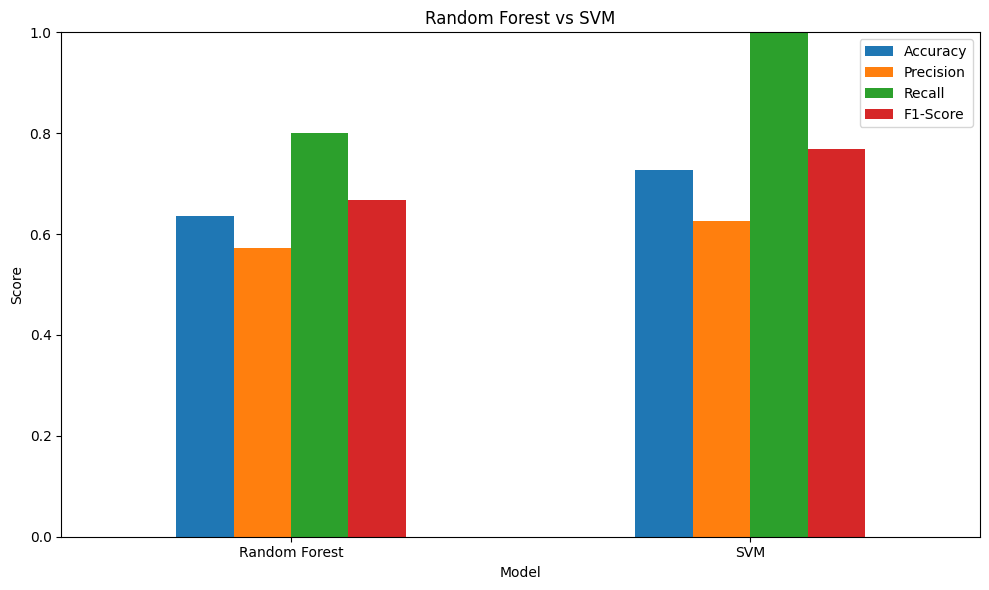

In [20]:
comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Random Forest vs SVM")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [21]:
feature_importance.to_csv(
    "genomic_feature_importance.csv",
    index=False
)

comparison.to_csv(
    "model_comparison.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!
